# Classification de chiffres manuscrits avec un MLP et PyTorch

## 1. Présentation du projet

### 1.1. Contexte

Le Deep Learning est une branche du Machine Learning qui repose sur l'utilisation de réseaux de neurones artificiels capables d'apprendre des représentations à partir des données.

Parmi les architectures fondamentales du Deep Learning, le **Multilayer Perceptron (MLP)** est un réseau de neurones constitué d'une couche d'entrée, d'une ou plusieurs couches cachées et d'une couche de sortie.

Dans ce projet, nous allons utiliser un MLP pour résoudre un problème de classification d'images à l'aide de la bibliothèque PyTorch.

### 1.2. Problématique

Comment construire, entraîner et évaluer un réseau de neurones multicouche capable de reconnaître automatiquement des chiffres manuscrits à partir d'images en niveaux de gris ?

### 1.3. Objectif général

Développer un modèle de Deep Learning capable de classifier des images de chiffres manuscrits de 0 à 9 en utilisant PyTorch.

### 1.4. Objectifs spécifiques

- Comprendre la structure du dataset MNIST.
- Explorer et visualiser les données.
- Préparer les images pour leur utilisation dans un MLP.
- Construire une architecture de réseau de neurones multicouche.
- Comprendre le fonctionnement de la rétropropagation et de l'optimisation des poids.
- Entraîner le modèle et suivre ses performances.
- Évaluer sa capacité de généralisation sur des données de test.
- Analyser les prédictions correctes et incorrectes.
- Identifier des pistes d'amélioration du modèle.

### 1.5. Outils et technologies

- **Python** : langage de programmation.
- **PyTorch** : construction et entraînement du réseau de neurones.
- **TorchVision** : téléchargement et préparation du dataset MNIST.
- **Matplotlib** : visualisation des images et des résultats.
- **Jupyter Notebook** : environnement interactif de développement et de documentation.

## 2. Présentation du dataset MNIST

### 2.1. Description

MNIST (*Modified National Institute of Standards and Technology*) est un dataset de référence en reconnaissance de chiffres manuscrits.

Il contient des images représentant les chiffres de 0 à 9. Chaque image est représentée en niveaux de gris et possède une résolution de 28 × 28 pixels.

Le dataset est divisé en deux ensembles :

| Ensemble | Nombre d'images | Utilisation |
|---|---:|---|
| Entraînement | 60 000 | Apprentissage des paramètres du modèle |
| Test | 10 000 | Évaluation finale du modèle |

### 2.2. Caractéristiques des données

Chaque image possède les caractéristiques suivantes :

- Hauteur : 28 pixels.
- Largeur : 28 pixels.
- Nombre de canaux : 1.
- Nombre de pixels : 784.
- Nombre de classes : 10.

Les classes correspondent aux chiffres allant de 0 à 9.

### 2.3. Nature du problème

Il s'agit d'un problème d'apprentissage supervisé, car chaque image est associée à une étiquette indiquant le chiffre qu'elle représente.

Plus précisément, il s'agit d'un problème de classification multiclasse.

### 2.4. Principe de résolution

Le modèle recevra une image de chiffre manuscrit en entrée et produira dix scores correspondant aux classes possibles.

La classe associée au score le plus élevé sera considérée comme la prédiction du modèle.

## 3. Préparation de l'environnement

Avant de commencer l'expérimentation, nous devons importer les bibliothèques nécessaires.

PyTorch sera utilisé pour construire et entraîner le réseau de neurones. TorchVision permettra de charger le dataset MNIST. Matplotlib sera utilisé pour visualiser les images et analyser les résultats.

Les principales fonctionnalités utilisées sont :

- `torch` : manipulation des tenseurs et opérations numériques.
- `torch.nn` : construction des couches et fonctions de perte.
- `torch.optim` : algorithmes d'optimisation.
- `torch.utils.data.DataLoader` : chargement des données par lots.
- `torchvision.datasets` : accès au dataset MNIST.
- `torchvision.transforms` : transformation des images.
- `matplotlib.pyplot` : visualisation graphique.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import matplotlib.pyplot as plt

print("Version de PyTorch :", torch.__version__)
print("Version de TorchVision :", __import__("torchvision").__version__)
print("GPU disponible :", torch.cuda.is_available())

Version de PyTorch : 2.3.1+cpu
Version de TorchVision : 0.18.1+cpu
GPU disponible : False


### 3.1. Configuration expérimentale

Nous allons définir les paramètres principaux de notre expérimentation.

Les hyperparamètres retenus pour cette première version sont :

| Hyperparamètre | Valeur | Description |
|---|---:|---|
| Taille du batch | 64 | Nombre d'images traitées par lot |
| Nombre d'époques | 5 | Nombre de passages sur l'ensemble d'entraînement |
| Learning rate | 0,001 | Taux d'apprentissage de l'optimiseur |
| Première couche cachée | 256 neurones | Première couche intermédiaire |
| Deuxième couche cachée | 128 neurones | Deuxième couche intermédiaire |
| Optimiseur | Adam | Algorithme de mise à jour des paramètres |
| Fonction de perte | CrossEntropyLoss | Mesure de l'erreur de classification |

Ces valeurs constituent une configuration initiale. Elles pourront être modifiées ultérieurement afin d'étudier leur influence sur les performances du modèle.

In [2]:
BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 0.001

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Appareil utilisé :", DEVICE)

Appareil utilisé : cpu


## 4. Chargement du dataset MNIST

### 4.1. Objectif

Nous allons télécharger le dataset MNIST et charger les ensembles d'entraînement et de test.

Nous utiliserons `torchvision.datasets.MNIST`, qui permet d'accéder directement aux données.

La transformation `transforms.ToTensor()` convertit chaque image en tenseur PyTorch de forme `(1, 28, 28)` et transforme les valeurs des pixels en nombres flottants compris entre 0 et 1.

### 4.2. Séparation des données

Nous utiliserons les 60 000 images de l'ensemble d'entraînement pour apprendre les paramètres du modèle et les 10 000 images de l'ensemble de test pour évaluer ses performances finales.

L'ensemble de test ne doit pas être utilisé pour ajuster les paramètres du réseau.

In [3]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Nombre d'images d'entraînement :", len(train_dataset))
print("Nombre d'images de test :", len(test_dataset))

Nombre d'images d'entraînement : 60000
Nombre d'images de test : 10000


### 4.3. Vérification du chargement

Après le chargement, nous allons vérifier que les données sont accessibles et que leur structure correspond à celle attendue.

Cette vérification permettra de confirmer :

- Le nombre d'exemples disponibles.
- La forme des images.
- Le type des tenseurs.
- La nature des étiquettes.
- L'intervalle des valeurs des pixels.

Forme de l'image : torch.Size([1, 28, 28])
Type des données : torch.float32
Label : 5
Valeur minimale : 0.0
Valeur maximale : 1.0


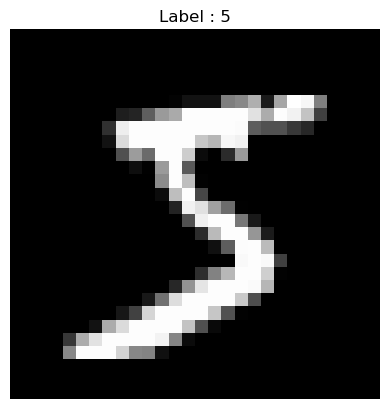

In [4]:
image, label = train_dataset[0]

print("Forme de l'image :", image.shape)
print("Type des données :", image.dtype)
print("Label :", label)
print("Valeur minimale :", image.min().item())
print("Valeur maximale :", image.max().item())

plt.imshow(image.squeeze(0), cmap="gray")
plt.title(f"Label : {label}")
plt.axis("off")
plt.show()

## 5. Exploration des données

### 5.1. Objectif

L'exploration des données permet de mieux comprendre les exemples utilisés pour entraîner le modèle avant de commencer l'apprentissage.

Nous allons visualiser plusieurs images, examiner leurs étiquettes et étudier la distribution des classes.

### 5.2. Visualisation des images

L'affichage d'un échantillon d'images permet d'observer la diversité de l'écriture manuscrite et les variations de forme entre les chiffres d'une même classe.

### 5.3. Distribution des classes

L'analyse de la distribution des étiquettes permet de vérifier si certaines classes sont davantage représentées que d'autres.

Cette étape est utile pour interpréter les performances du classificateur et repérer un éventuel déséquilibre entre les classes.

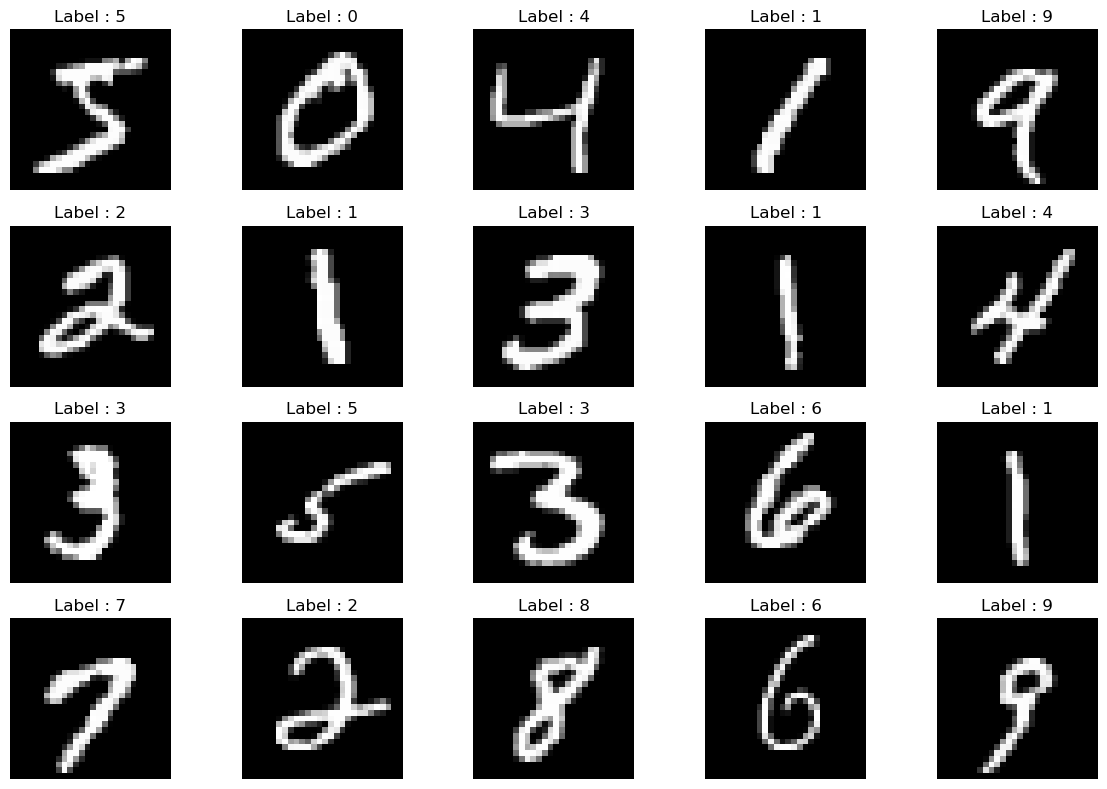

In [5]:
plt.figure(figsize=(12, 8))

for i in range(20):
    image, label = train_dataset[i]

    plt.subplot(4, 5, i + 1)
    plt.imshow(image.squeeze(0), cmap="gray")
    plt.title(f"Label : {label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

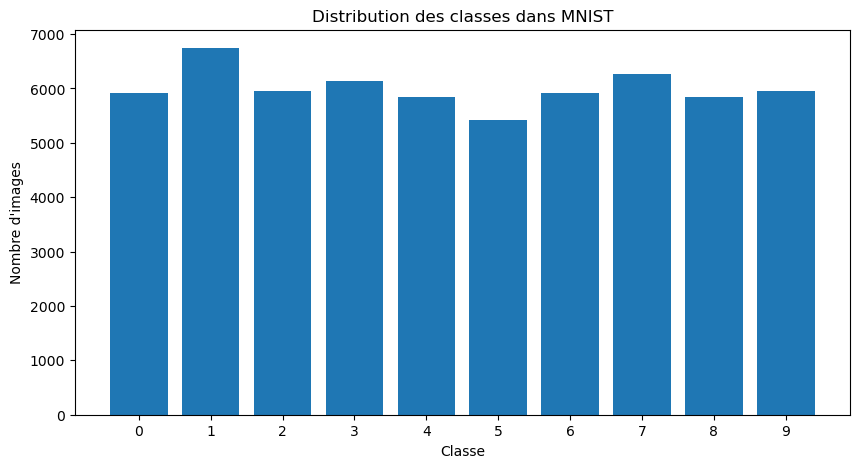

Nombre d'images par classe :
Chiffre 0 : 5923
Chiffre 1 : 6742
Chiffre 2 : 5958
Chiffre 3 : 6131
Chiffre 4 : 5842
Chiffre 5 : 5421
Chiffre 6 : 5918
Chiffre 7 : 6265
Chiffre 8 : 5851
Chiffre 9 : 5949


In [6]:
labels = train_dataset.targets

class_counts = torch.bincount(labels, minlength=10)

plt.figure(figsize=(10, 5))
plt.bar(range(10), class_counts.numpy())

plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.title("Distribution des classes dans MNIST")
plt.xticks(range(10))

plt.show()

print("Nombre d'images par classe :")

for digit, count in enumerate(class_counts.tolist()):
    print(f"Chiffre {digit} : {count}")

### 5.4. Interprétation des observations

Après avoir visualisé les images et étudié la distribution des classes, nous pouvons examiner les caractéristiques principales du dataset.

Les images présentent différentes formes d'écriture manuscrite pour une même classe. Le modèle devra donc apprendre des caractéristiques suffisamment générales pour reconnaître un chiffre malgré les variations entre les écritures.

L'analyse de la distribution des classes permet également de vérifier si les exemples sont répartis de manière relativement équilibrée.

**Observations personnelles :**

- Les variations d'écriture observées sont nombreuses
- Les classes qui semblent les plus difficiles à distinguer sont 5 et 6 
- Les classes ne sont pas equilibrées
- Les conséquences possibles pour l'apprentissage sont la reconnaisance de certaine par rapport a d'autres 

## 6. Prétraitement et préparation des données

### 6.1. Transformation des images

Les images MNIST possèdent une forme de `(1, 28, 28)`. Cependant, un MLP classique attend un vecteur de caractéristiques en entrée.

Nous devons donc convertir chaque image en un vecteur de 784 valeurs :

\[
28 \times 28 = 784
\]

Cette opération sera réalisée dans le modèle avec la couche `nn.Flatten()`.

### 6.2. Normalisation des pixels

La transformation `ToTensor()` convertit les valeurs des pixels en nombres flottants compris entre 0 et 1.

Cette mise à l'échelle constitue une préparation simple des données. Dans notre première expérience, nous conserverons cette transformation sans appliquer de normalisation supplémentaire.

### 6.3. Chargement par lots

Nous utiliserons `DataLoader` pour fournir les exemples au modèle par lots de 64 images.

Le mélange des données d'entraînement permettra de modifier l'ordre de présentation des exemples à chaque époque. En revanche, les données de test seront parcourues sans mélange.

Cette organisation facilite l'entraînement et la gestion des données dans PyTorch.

In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("Forme d'un batch d'images :", images.shape)
print("Forme d'un batch de labels :", labels.shape)

Forme d'un batch d'images : torch.Size([64, 1, 28, 28])
Forme d'un batch de labels : torch.Size([64])


### 6.4. Vérification des dimensions

Un lot d'entraînement contient 64 images de forme `(1, 28, 28)`.

Sa forme globale est donc :

\[
(64,1,28,28)
\]

Après aplatissement, le lot aura la forme :

\[
(64,784)
\]

La première dimension représente le nombre d'images, tandis que la deuxième correspond au nombre de caractéristiques de chaque image.

Cette vérification permet de s'assurer que les dimensions des données sont compatibles avec la première couche du MLP.

In [9]:
flatten = nn.Flatten()

flattened_images = flatten(images)

print("Avant aplatissement :", images.shape)
print("Après aplatissement :", flattened_images.shape)

Avant aplatissement : torch.Size([64, 1, 28, 28])
Après aplatissement : torch.Size([64, 784])


## 7. Construction du réseau de neurones

### 7.1. Principe du MLP

Un perceptron multicouche est un réseau de neurones artificiels constitué de plusieurs couches entièrement connectées.

Chaque couche transforme les représentations reçues de la couche précédente. Les fonctions d'activation introduisent des non-linéarités permettant au réseau d'apprendre des relations complexes.

### 7.2. Architecture retenue

Nous allons construire un MLP composé des couches suivantes :

\[
784 \rightarrow 256 \rightarrow 128 \rightarrow 10
\]

| Couche | Dimension d'entrée | Dimension de sortie | Fonction |
|---|---:|---:|---|
| Aplatissement | Image 28 × 28 | 784 | Conversion en vecteur |
| Couche linéaire 1 | 784 | 256 | Transformation des caractéristiques |
| ReLU | 256 | 256 | Activation non linéaire |
| Couche linéaire 2 | 256 | 128 | Transformation intermédiaire |
| ReLU | 128 | 128 | Activation non linéaire |
| Couche de sortie | 128 | 10 | Calcul des scores des classes |

### 7.3. Fonction d'activation

Nous utiliserons ReLU dans les couches cachées :

\[
ReLU(x)=\max(0,x)
\]

Cette fonction introduit une non-linéarité dans le réseau.

### 7.4. Couche de sortie

La dernière couche possède dix neurones, un pour chaque chiffre possible.

Elle renvoie dix scores, appelés *logits*. Nous utiliserons ces scores directement avec la fonction de perte `CrossEntropyLoss`, sans ajouter de couche Softmax dans le modèle.

In [10]:
class MNIST_MLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.network = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.network(x)

        return x

### 7.5. Initialisation du modèle

Après avoir défini l'architecture, nous allons instancier le réseau et le placer sur le dispositif de calcul disponible.

Le modèle sera exécuté sur le GPU si CUDA est disponible. Dans le cas contraire, il sera exécuté sur le CPU.

Nous allons également vérifier les dimensions de la sortie du réseau pour confirmer que chaque image produit dix scores.

In [11]:
model = MNIST_MLP().to(DEVICE)

print(model)

images, labels = next(iter(train_loader))

images = images.to(DEVICE)

outputs = model(images)

print("Forme de l'entrée :", images.shape)
print("Forme de la sortie :", outputs.shape)

MNIST_MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Forme de l'entrée : torch.Size([64, 1, 28, 28])
Forme de la sortie : torch.Size([64, 10])


### 7.6. Nombre de paramètres entraînables

Chaque couche linéaire possède des poids et des biais qui seront appris pendant l'entraînement.

Pour une couche linéaire comportant \(n_{in}\) entrées et \(n_{out}\) sorties, le nombre de paramètres est :

\[
N = n_{in}\times n_{out}+n_{out}
\]

Le premier terme correspond aux poids et le second aux biais.

Nous allons calculer le nombre total de paramètres entraînables du réseau afin de mieux comprendre sa taille et sa complexité.

In [12]:
total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Nombre de paramètres entraînables :", total_params)

Nombre de paramètres entraînables : 235146


## 8. Configuration de l'entraînement

### 8.1. Fonction de perte

Nous utiliserons `nn.CrossEntropyLoss()` pour mesurer l'écart entre les scores produits par le réseau et les classes réelles.

Cette fonction est adaptée aux problèmes de classification multiclasse.

Elle utilise les logits produits par le réseau et les labels sous forme d'entiers compris entre 0 et 9.

### 8.2. Algorithme d'optimisation

Nous utiliserons l'algorithme Adam pour mettre à jour les paramètres du réseau à partir des gradients calculés par rétropropagation.

Le taux d'apprentissage initial sera fixé à 0,001.

### 8.3. Principe de l'apprentissage

L'apprentissage repose sur les étapes suivantes :

1. Calculer les prédictions du réseau (*forward pass*).
2. Calculer la fonction de perte.
3. Réinitialiser les gradients avant le calcul de chaque nouveau lot.
4. Calculer les gradients avec la rétropropagation.
5. Mettre à jour les paramètres avec l'optimiseur.

Ces opérations seront répétées pour chaque lot de données et pendant plusieurs époques.

In [13]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Fonction de perte :", criterion)
print("Optimiseur :", optimizer)

Fonction de perte : CrossEntropyLoss()
Optimiseur : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 9. Entraînement du modèle

### 9.1. Objectif

L'objectif de cette étape est d'apprendre les paramètres du MLP à partir des 60 000 images d'entraînement.

À chaque époque, le modèle parcourt l'ensemble des données. Pour chaque lot, il calcule ses prédictions, mesure son erreur et ajuste ses paramètres.

### 9.2. Mode entraînement

Nous utiliserons `model.train()` pour placer le réseau en mode entraînement.

Les gradients seront calculés avec `loss.backward()`, puis l'optimiseur mettra à jour les paramètres avec `optimizer.step()`.

L'appel à `optimizer.zero_grad()` permettra de réinitialiser les gradients avant chaque nouveau calcul.

### 9.3. Indicateurs de suivi

Nous suivrons deux indicateurs :

- **Training loss** : mesure moyenne de l'erreur de classification sur les données d'entraînement.
- **Training accuracy** : proportion d'images correctement classées sur les données d'entraînement.

La diminution de la loss et l'augmentation de l'accuracy peuvent indiquer que le modèle apprend à partir des données.

In [14]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = 100 * correct / total

    return average_loss, accuracy

### 9.4. Exécution de l'entraînement

Nous allons entraîner le réseau pendant cinq époques.

Les métriques calculées à la fin de chaque époque seront enregistrées afin de pouvoir étudier leur évolution.

Cette première expérimentation servira de référence pour les prochaines améliorations du modèle.

In [16]:
history = {
    "train_loss": [],
    "train_accuracy": []
}

for epoch in range(EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {train_accuracy:.2f}%"
    )

Epoch [1/5] | Loss: 0.0304 | Accuracy: 98.97%
Epoch [2/5] | Loss: 0.0226 | Accuracy: 99.28%
Epoch [3/5] | Loss: 0.0211 | Accuracy: 99.31%
Epoch [4/5] | Loss: 0.0165 | Accuracy: 99.46%
Epoch [5/5] | Loss: 0.0153 | Accuracy: 99.45%


### 9.5. Visualisation des métriques d'entraînement

L'évolution de la loss et de l'accuracy permet de suivre le comportement du réseau au cours de l'apprentissage.

Nous allons représenter ces deux métriques en fonction du nombre d'époques.

Cette visualisation permettra de vérifier si la loss diminue et si l'accuracy progresse au fil de l'entraînement.

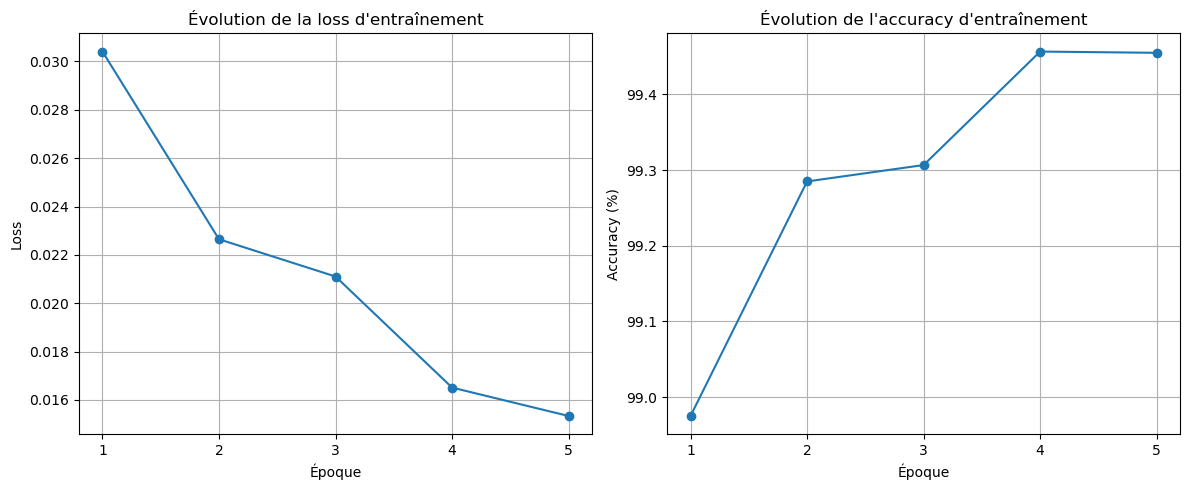

In [17]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], marker="o")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Évolution de la loss d'entraînement")
plt.xticks(list(epochs_range))
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_accuracy"], marker="o")
plt.xlabel("Époque")
plt.ylabel("Accuracy (%)")
plt.title("Évolution de l'accuracy d'entraînement")
plt.xticks(list(epochs_range))
plt.grid(True)

plt.tight_layout()
plt.show()

## 10. Évaluation du modèle

### 10.1. Objectif

Après l'entraînement, nous allons mesurer la capacité du modèle à classifier des images qui n'ont pas été utilisées pour ajuster ses paramètres.

Nous utiliserons pour cela l'ensemble de test de MNIST, constitué de 10 000 images.

### 10.2. Métriques

Nous calculerons :

- **Test loss** : mesure moyenne de l'erreur de classification sur les données de test.
- **Test accuracy** : proportion d'images correctement classées.

### 10.3. Précautions

L'évaluation sera réalisée en mode `model.eval()` et dans un contexte `torch.no_grad()` afin de désactiver les comportements spécifiques à l'entraînement et d'éviter le calcul des gradients.

L'ensemble de test sera réservé à l'évaluation finale. Si nous souhaitons comparer plusieurs architectures et sélectionner la meilleure, il sera préférable d'introduire un ensemble de validation distinct.

In [18]:
def evaluate(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = 100 * correct / total

    return average_loss, accuracy

In [19]:
test_loss, test_accuracy = evaluate(
    model,
    test_loader,
    criterion,
    DEVICE
)

print(f"Test loss : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.2f}%")

Test loss : 0.0896
Test accuracy : 97.84%


### 10.4. Interprétation des résultats

Les performances obtenues sur les données de test permettent d'évaluer la capacité de généralisation du modèle.

Nous devons comparer les résultats de test avec ceux obtenus sur les données d'entraînement.

Une différence importante entre les performances d'entraînement et de test peut indiquer un problème de généralisation. Toutefois, elle ne suffit pas à elle seule pour conclure à un surapprentissage.

**Résultats de l'expérimentation :**

- Loss finale d'entraînement :
- Accuracy finale d'entraînement :
- Loss sur le test :
- Accuracy sur le test :

**Analyse personnelle :**

- Le modèle semble-t-il apprendre correctement ?
- Les performances de test sont-elles proches de celles de l'entraînement ?
- Quels éléments pourraient expliquer les résultats obtenus ?
- Quelles modifications pourrait-on tester pour améliorer le modèle ?

## 11. Analyse des prédictions

### 11.1. Objectif

L'accuracy fournit une mesure globale des performances, mais elle ne permet pas d'identifier précisément les types d'erreurs commises par le modèle.

Nous allons visualiser plusieurs prédictions afin de comparer le chiffre réel au chiffre prédit.

### 11.2. Analyse qualitative

Pour chaque image, nous afficherons :

- L'image manuscrite.
- Le label réel.
- Le label prédit par le réseau.

Cette analyse permettra de repérer les exemples correctement classés et les cas où le modèle se trompe.

### 11.3. Intérêt

L'examen des erreurs permet de mieux comprendre les limites du modèle et d'identifier les situations pour lesquelles une amélioration de l'architecture ou de la préparation des données pourrait être utile.

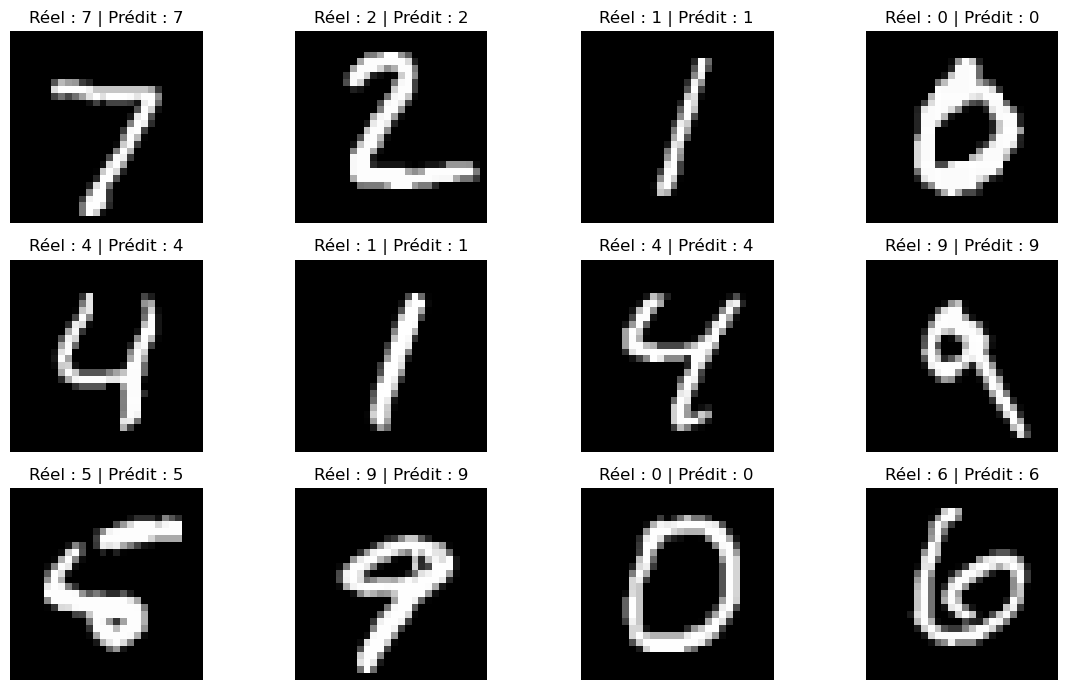

In [20]:
model.eval()

images, labels = next(iter(test_loader))

images_device = images.to(DEVICE)

with torch.no_grad():
    outputs = model(images_device)
    predictions = outputs.argmax(dim=1).cpu()

plt.figure(figsize=(12, 7))

for i in range(12):

    plt.subplot(3, 4, i + 1)

    plt.imshow(images[i].squeeze(0), cmap="gray")

    true_label = labels[i].item()
    predicted_label = predictions[i].item()

    plt.title(
        f"Réel : {true_label} | Prédit : {predicted_label}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

### 11.4. Analyse des erreurs

Pour approfondir l'évaluation, nous allons examiner les exemples pour lesquels le modèle produit une prédiction incorrecte.

Cette analyse permettra de comprendre si certaines images présentent des formes difficiles à distinguer ou si certaines classes sont plus souvent confondues.

**Observations :**

- Exemples de chiffres mal classés :
- Types de confusions observées :
- Caractéristiques visuelles des images difficiles :
- Hypothèses expliquant les erreurs :
- Améliorations envisageables :

In [21]:
model.eval()

misclassified_images = []
misclassified_labels = []
misclassified_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images_device = images.to(DEVICE)

        outputs = model(images_device)
        predictions = outputs.argmax(dim=1).cpu()

        mask = predictions != labels

        if mask.any():

            misclassified_images.append(images[mask])
            misclassified_labels.append(labels[mask])
            misclassified_predictions.append(predictions[mask])

misclassified_images = torch.cat(misclassified_images)
misclassified_labels = torch.cat(misclassified_labels)
misclassified_predictions = torch.cat(misclassified_predictions)

print(
    "Nombre d'images mal classées :",
    len(misclassified_labels)
)

print(
    "Taux d'erreur :",
    f"{100 * len(misclassified_labels) / len(test_dataset):.2f}%"
)

Nombre d'images mal classées : 216
Taux d'erreur : 2.16%


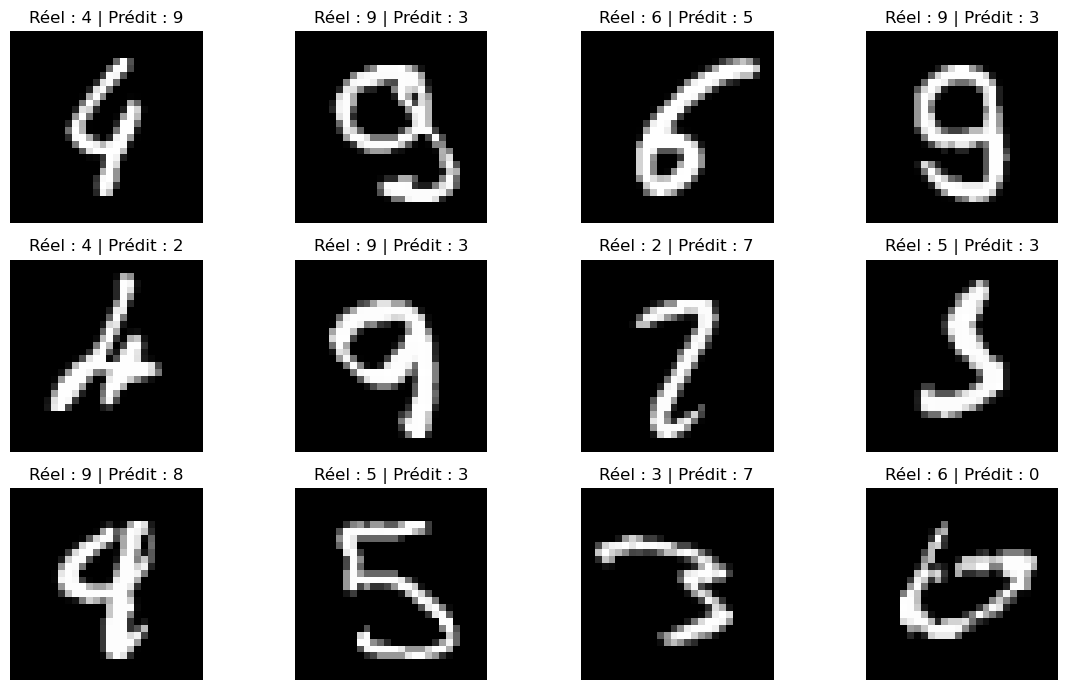

In [22]:
n_images = min(12, len(misclassified_labels))

plt.figure(figsize=(12, 7))

for i in range(n_images):

    plt.subplot(3, 4, i + 1)

    plt.imshow(misclassified_images[i].squeeze(0), cmap="gray")

    true_label = misclassified_labels[i].item()
    predicted_label = misclassified_predictions[i].item()

    plt.title(
        f"Réel : {true_label} | Prédit : {predicted_label}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## 12. Conclusion générale

### 12.1. Bilan

Ce projet nous a permis de mettre en pratique les concepts fondamentaux des réseaux de neurones multicouches à travers un problème de classification d'images.

Nous avons chargé et exploré le dataset MNIST, préparé les données, construit un MLP avec PyTorch, configuré l'apprentissage et évalué les performances du modèle sur des données de test.

Nous avons également étudié l'évolution des métriques d'entraînement et examiné plusieurs prédictions afin de mieux comprendre le comportement du réseau.

### 12.2. Compétences mobilisées

- Manipulation de tenseurs PyTorch.
- Préparation et chargement de données.
- Construction d'un réseau de neurones avec `nn.Module`.
- Utilisation de couches linéaires et de fonctions d'activation.
- Compréhension de la rétropropagation.
- Utilisation d'un optimiseur et d'une fonction de perte.
- Mise en place d'une boucle d'entraînement.
- Évaluation d'un modèle de classification.
- Visualisation et analyse des résultats.

### 12.3. Limites

Le MLP traite chaque image comme un vecteur de pixels. L'aplatissement supprime la structure spatiale explicite de l'image, ce qui limite sa capacité à exploiter directement les relations entre les pixels voisins.

Par ailleurs, les performances d'une seule expérimentation ne suffisent pas à déterminer la meilleure architecture ni les meilleurs hyperparamètres.

### 12.4. Perspectives d'amélioration

Plusieurs pistes peuvent être explorées :

1. Comparer différentes architectures de MLP.
2. Étudier l'influence du nombre de neurones et de couches cachées.
3. Comparer plusieurs optimiseurs et taux d'apprentissage.
4. Ajouter un ensemble de validation pour suivre la généralisation.
5. Tester des techniques de régularisation, comme Dropout et weight decay.
6. Analyser les erreurs avec une matrice de confusion.
7. Comparer le MLP à un réseau de neurones convolutif (CNN).
8. Enregistrer le modèle entraîné et développer une interface permettant de tester des images personnalisées.

### 12.5. Conclusion personnelle

Cette première expérimentation constitue une base pour approfondir l'apprentissage profond avec PyTorch. Les prochaines étapes consisteront à mener des expériences comparatives, à analyser les résultats et à justifier les choix d'architecture à partir de mesures objectives.